<div style="background-color: #f5f5f5; padding: 20px; border-radius: 10px; border: 1px solid #e0e0e0;">
<table style="width:100%; border:none;">
  <tbody><tr style="border:none;">
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
    <td style="width:60%; text-align:center; border:none; vertical-align:middle;">
      <h1 style="margin:0; color:#333;">University of Isfahan</h1>
      <h2 style="margin:0; color:#555; font-weight:normal;">Faculty of Mathematics and Statistics</h2>
      <br/>
      <hr style="border: 1px solid #ccc; margin-top:15px; margin-bottom:15px;">
      <h3 style="margin:0; color:#0056b3;">Second Practical Homework: Regularized Logistic Regression</h3>
      <br/>
      <h4 style="margin:0; font-size: 1.1em; color: #333; line-height: 1.6; margin-top: 15px; display: inline-block;">
        <strong>Course:</strong> Machine Learning<br>
        <strong>Instructor:</strong> Dr. Mohsen Alambardar<br>
        <strong>Semester:</strong> Fall 1404-1405
      </h4>
    </td>
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
  </tr>
</tbody></table>
</div>

<div style="background-color: #f5f5f5; border: 1px solid #f5f5f5; padding: 20px; border-radius: 10px; margin-top: 25px; margin-bottom: 25px;">
  
  <h3 style="text-align: center; margin-top: 0; color: #0056b3;">Student Information</h3>
  <p style="text-align: center; color: #555; margin-bottom: 20px; margin-top: 0;">
    Please fill in your details below.
  </p>

  <table style="width: 60%; margin-left: auto; margin-right: auto; border: none; font-size: 1.1em; color: #333;">
    <tbody>
      <tr>
        <td style="text-align: right; padding: 8px; width: 35%;"><strong>Student Name:</strong></td>
        <td style="text-align: left; padding: 8px;"><em>Hosna Soltanolkottabi</em></td> <!-- UPDATE THIS LINE -->
      </tr>
      <tr>
        <td style="text-align: right; padding: 8px;"><strong>Student ID:</strong></td>
        <td style="text-align: left; padding: 8px;"><em></em></td>  <!-- UPDATE THIS LINE -->
      </tr>
    </tbody>
  </table>
  
</div>

# **HW2-P: Regularization in Logistic Regression**

[This notebook will guide you through a hands-on exercise to understand **regularization**. Regularization is a crucial technique to prevent **overfitting** in machine learning models.

**Our goal:** We will explore how regularization works by:
1.  First, creating a non-linear logistic regression model that clearly **overfits** the training data.
2.  Then, applying **L2 Regularization (Ridge)** to see how it smooths the decision boundary and creates a more general model.
3.  Finally, comparing the effects of **L1 (Lasso)** and **L2 (Ridge)** regularization on model coefficients to understand feature selection.

You will be using `sklearn`'s `Pipeline`, `PolynomialFeatures`, and `LogisticRegression` tools, which you saw in the workshops.

---

## **1. Setup: Importing Libraries**

First, we'll import the necessary libraries. We'll also add two helper functions that were used in your workshops: `plot_2d_separator` for visualizing decision boundaries and a function to plot model coefficients.

### **Libraries and Defaults**

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, load_breast_cancer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Set default figure size
plt.rcParams['figure.figsize'] = (10, 6)
plt.style.use('ggplot')

### **Helper Function `plot_2d_separator`**

In [3]:
# Helper function from your workshop to plot decision boundaries

def plot_2d_separator(classifier, X, fill=False, ax=None, eps=None):
    """Plots the decision boundary of a classifier."""
    if eps is None:
        eps = X.std() / 2.

    x_min, x_max = X[:, 0].min() - eps, X[:, 0].max() + eps
    y_min, y_max = X[:, 1].min() - eps, X[:, 1].max() + eps
    xx = np.linspace(x_min, x_max, 100)
    yy = np.linspace(y_min, y_max, 100)

    X1, X2 = np.meshgrid(xx, yy)
    X_grid = np.c_[X1.ravel(), X2.ravel()]
    try:
        decision_values = classifier.decision_function(X_grid)
        levels = [0]
        fill_levels = [decision_values.min(), 0, decision_values.max()]
    except AttributeError:
        # no decision_function
        decision_values = classifier.predict_proba(X_grid)[:, 1]
        levels = [.5]
        fill_levels = [0, .5, 1]

    if ax is None:
        ax = plt.gca()
    if fill:
        ax.contourf(X1, X2, decision_values.reshape(X1.shape),
                    levels=fill_levels, colors=['blue', 'red'], alpha=0.1)
    ax.contour(X1, X2, decision_values.reshape(X1.shape), levels=levels,
               colors="black", linestyles=['--'])
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(())
    ax.set_yticks(())

### **Helper Function `plot_coefficients`**

In [4]:
# Helper function based on your workshop to plot model coefficients

def plot_coefficients(model, feature_names, title):
    """Plots the coefficients of a linear model."""
    if hasattr(model, 'coef_'):
        # Get coefficients
        coef = model.coef_

        # Handle multi-class logistic regression
        if coef.ndim > 1:
            # For simplicity, just plot the first class's coefficients
            coef = coef[0]

        plt.figure(figsize=(12, 7))
        plt.bar(range(len(coef)), coef)
        plt.xticks(range(len(coef)), feature_names, rotation=90)
        plt.axhline(0, color='black', linestyle='--')
        plt.title(title)
        plt.ylabel('Coefficient Value')
        plt.show()
    else:
        print("This model does not have a '.coef_' attribute.")

---

## **2. Part 1: Creating an Overfit Model**

### **Load and Plot Data**

First, let's create a dataset. We'll use `make_moons`, which is a "toy" dataset provided by `sklearn`. It's not real data, but it's very useful for visualizing how algorithms work.

* `X` will be a 2D array (100 rows, 2 columns) where each row is a point with an $(x, y)$ coordinate.
* `y` will be a 1D array (100 rows) with the class label (0 or 1) for each point.

The data is shaped like two crescent moons, which makes it impossible to separate with a single straight line. This is called a **non-linearly separable** dataset.

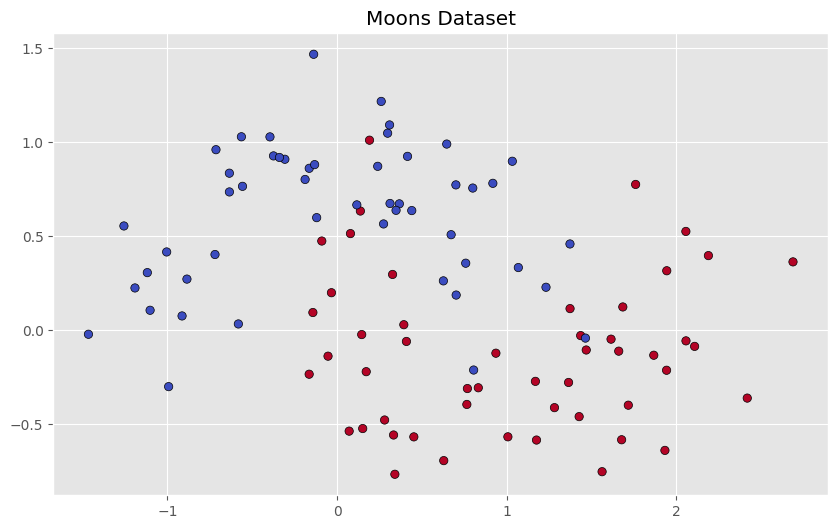

In [5]:
# Generate and plot the dataset
X, y = make_moons(n_samples=100, noise=0.25, random_state=42)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
plt.title('Moons Dataset')
plt.show()

### **Creating the Pipeline**

A simple logistic regression model can only create a linear decision boundary. To fit this "moon" shape, we need to create non-linear features. As you saw in the workshop, we can use `PolynomialFeatures` for this.

We will create a `Pipeline` that:
1.  Generates high-degree polynomial features (degree 15) to be able to capture complex shapes.
2.  Scales the data using `StandardScaler`, which is very important for regularization.
3.  Fits a `LogisticRegression` model.

To **force** the model to overfit, we will set the regularization parameter `C` to a very large value (`C=1e6`).

**Recall:** `C` is the *inverse* of the regularization strength $\lambda$.
* Large `C` = Small $\lambda$ = **Weak** regularization.
* Small `C` = Large $\lambda$ = **Strong** regularization.

By setting `C=1e6`, we are essentially telling the model *not* to use regularization, which will lead to overfitting.

<br/>

#### **How does the training work?**

In the next cell, you will call `overfit_pipeline.fit(X, y)`. This single command starts the "learning" process. Here is what happens inside the pipeline:

1.  **Step 1 (`poly`):** The `PolynomialFeatures` transformer takes your `X` data (100x2) and creates a new, much larger feature matrix, `X_poly`. With degree 15, this new matrix will have many columns (e.g., $x_1, x_2, x_1^2, x_1x_2, x_2^2, ..., x_2^{15}$).
2.  **Step 2 (`scaler`):** The `StandardScaler` takes `X_poly` and calculates the mean and standard deviation for *each* polynomial feature. It then "scales" the data by subtracting the mean and dividing by the standard deviation. This ensures all features are on a similar scale.
3.  **Step 3 (`model`):** The `LogisticRegression` model receives the scaled `X_poly` and the labels `y`. It then uses an optimization algorithm (we specified `solver='lbfgs'`) to find the best set of coefficients ($\theta$ values) that minimize the cost function (in this case, the Log-Loss).

Because our `C` is so large, the regularization penalty is near zero, so the model's *only* goal is to minimize the Log-Loss, which leads to it fitting the noisy training data perfectly.

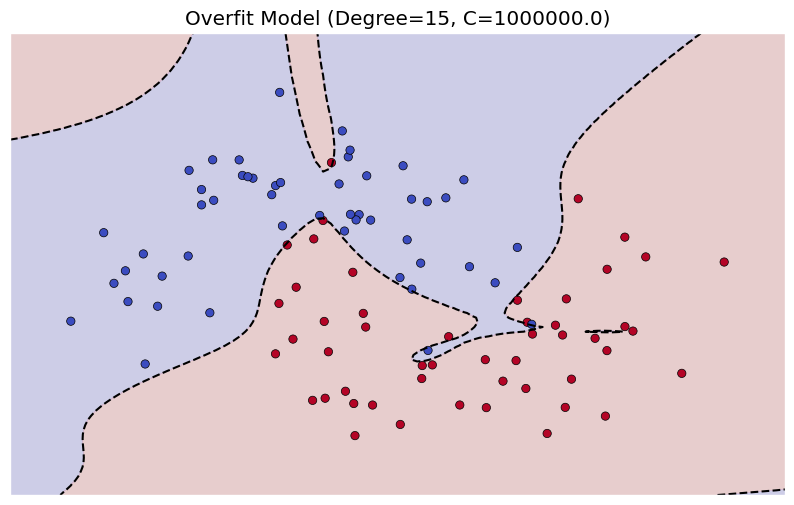

In [6]:
# We will use a high degree to allow the model to overfit
degree = 15
# We use a very large C to turn off regularization
C_overfit = 1e6

# --- YOUR TASK ---
# Create a pipeline with three steps:
# 1. 'poly': PolynomialFeatures with the specified degree.
# 2. 'scaler': StandardScaler.
# 3. 'model': LogisticRegression. Use penalty='l2', C=C_overfit,
#             solver='lbfgs', and max_iter=2000.

# TODO: Define the three components
poly_features = PolynomialFeatures(degree=degree)
scaler = StandardScaler()
log_reg_overfit = LogisticRegression(penalty='l2', C=C_overfit, solver='lbfgs', max_iter=2000)

# TODO: Create the pipeline
overfit_pipeline = Pipeline([
    ('poly', poly_features),
    ('scaler', scaler),
    ('model', log_reg_overfit)
])

# TODO: Fit the pipeline to the data (X, y)
overfit_pipeline.fit(X,y)

# --- End of YOUR TASK ---

# Plot the decision boundary
plot_2d_separator(overfit_pipeline, X, fill=True)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
plt.title(f'Overfit Model (Degree={degree}, C={C_overfit})')
plt.show()

### **Your Task 1: Analyze the Overfit Model**

**Instructions:** Look at the plot generated above and answer the following questions.

<br/>

**Question 1.1:** Does this decision boundary look like a good, generalizable model? Why or why not? (Hint: Look for small "islands" of one color in a sea of the other color).

**Your Answer 1.1:**
<p dir="rtl">
این مرز تصمیم‌گیری برای داده های آموزشی بسیار خوب بوده و خطای آن کم است اما برای داده های جدید اینگونه نیست و خطا زیاد است. برای مثال قسمتی جزیره مانند در پایین برای دو داده آموزشی که متعلق به کلاس آبی هستند ایجاد شده است اما مشخص است که اگر داده ای در اطراف این دو داده آبی رنگ باشند متعلق به کلاس قرمز است با این حال ماشین آن را متعلق به کلاس آبی تشخیص میدهد.
</p>

<br/>

**Question 1.2:** As mentioned, `C` is the *inverse* of the regularization strength $\lambda$ from the slides. What does a very large `C` (like `1e6`) imply about the value of $\lambda$? How does this explain the overfit model you see?

**Your Answer 1.2:**
<p dir="rtl">
میدانیم هرچه c بزرگ تر باشد لاندا کوچک تر است در نتیجه برای مقدار بسیار بزرگ C لاندا بسیار کوچک خواهد بود و یعنی اثر گذاری جمله مربوط به تنظیم در تابع بسیار کم خواهد بود. در نتیجه فقط منطبق بودن تابع با داده های آموزشی مهم خواهد بود و مرز تصمیم گیری طبق آن تعیین میشود و بیش پردازش رخ میدهد.
</p>
<br/>

---

## **3. Part 2: Fixing Overfitting with L2 Regularization**

Now, let's see if we can find a better model by applying L2 regularization. We will use the **same pipeline** as before, but this time we will try three different values for `C`:
* `C = 1e6` (Overfitting / No Regularization)
* `C = 1.0` (A "medium" amount of regularization)
* `C = 0.01` (Strong Regularization)

<br/>

#### **How does the training work in this loop?**

In the next cell, you will call `.fit()` *inside a loop*. Each time the loop runs, it creates a **brand new** pipeline with a different `C` value.

When `pipeline.fit(X, y)` is called, the *goal* of the `LogisticRegression` model's optimizer changes.
It is now trying to minimize a new, combined cost function:

$$J(\theta) = \text{[Log-Loss]} + \frac{\lambda}{2m}\sum_{j=1}^{n}\theta_{j}^{2}$$

* The optimizer must now find $\theta$ coefficients that **balance two goals**:
    1.  Fit the data (minimize the Log-Loss).
    2.  Keep the weights small (minimize the L2 penalty term).

* By changing `C` (which changes $\lambda$), we are changing the "importance" of the penalty.
    * A **small `C`** (large $\lambda$) tells the optimizer: "I care a lot about small weights! It's okay if you don't fit the data perfectly." This leads to a simpler, smoother boundary (underfitting).
    * A **large `C`** (small $\lambda$) tells the optimizer: "I mostly care about fitting the data! Ignore the penalty." This leads to a complex boundary (overfitting).

### **Loop, Fit, and Plot Regularized Models**

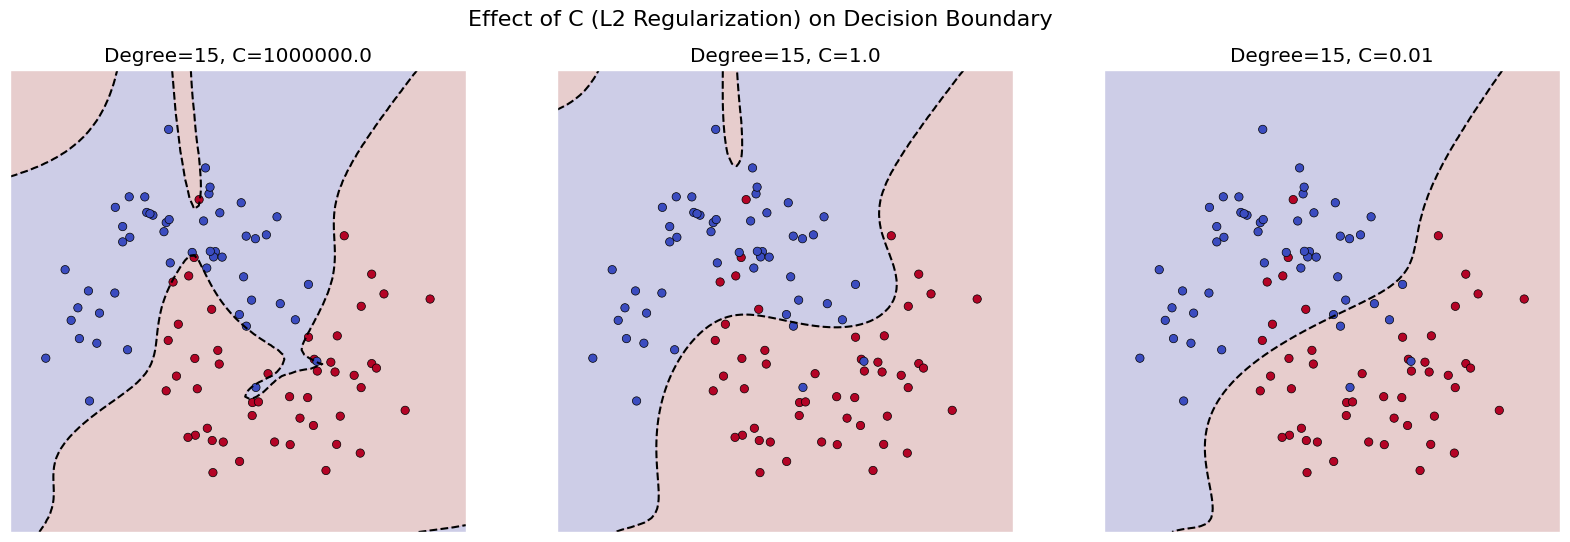

In [7]:
C_values = [1e6, 1.0, 0.01]
degree = 15

# Create a figure to hold our subplots
plt.figure(figsize=(20, 6))

# --- YOUR TASK ---
# Loop through the C_values. In each iteration:
# 1. Create a new Pipeline (like in Part 1) using the current `C` value.
#    (Remember to include poly, scaler, and the model).
# 2. Fit the pipeline to the (X, y) data.
# 3. Create a subplot and plot the decision boundary (use plot_2d_separator).

for i, C in enumerate(C_values):
    # Create a subplot
    ax = plt.subplot(1, len(C_values), i + 1)

    # TODO: Define the LogisticRegression model with the current C
    # Use penalty='l2', solver='lbfgs', max_iter=2000
    log_reg = LogisticRegression(penalty='l2', C=C, solver='lbfgs', max_iter=2000)

    # TODO: Create the full pipeline
    pipeline = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', log_reg)
    ])

    # TODO: Fit the pipeline
    pipeline.fit(X,y)

    # --- End of YOUR TASK ---

    # Plot the results
    plot_2d_separator(pipeline, X, fill=True, ax=ax)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
    ax.set_title(f'Degree={degree}, C={C}')

plt.suptitle('Effect of C (L2 Regularization) on Decision Boundary', fontsize=16)
plt.show()

### **Your Task 2: Analyze the Regularized Models**

**Instructions:** Observe the three plots you just generated and answer the following questions.

<br/>

**Question 2.1:** Describe what happened to the decision boundary as `C` decreased (and $\lambda$ increased). Label each of the three plots as **"Overfitting"**, **"Underfitting"**, or **"Good Fit"**.

**Your Answer 2.1:**
<p dir="rtl">
هنگامی که مقدار c کاهش پیدا میکند(لاندا افزایش) اثر گذاری بخش تنظیم در تابع خطا افزایش پیدا میکند در نتیجه با این که خطا داده آموزشی اندکی زیاد میشود اما مقادیر پارامترها(تتا ها) کاهش پیدا میکنند و در نتیجه مرز تصمیم گیری هموار تر میشود.
</p>

* **`C = 1e6`:**  خطا داده آموزشی کم و ناهموار و پیچیده *Overfitting*
* **`C = 1.0`:** خطا داده آموزشی بیشتر از حالت قبل ولی همچنان به خوبی دو کلاس را از هم جدا میکند همچنین هموار *Good Fit*
* **`C = 0.01`:** هموار تر از حالت قبلی(تقریبا خط صاف) و خطا داده آموزشی بیشتر از حالت قبل و دیگر به خوبی ساختار حلال ماه را تشخیص نمیده *Underfitting*

<br/>

**Question 2.2:** Explain *why* a smaller `C` (larger $\lambda$) results in a smoother, simpler boundary. How does the L2 penalty term $\frac{\lambda}{2}\sum_{j=1}^{n}\theta_{j}^{2}$ achieve this? (Hint: What does the penalty do to the $\theta$ coefficients of the high-degree polynomial features?)

**Your Answer 2.2:**
<p dir= "rtl">
طبق عبارت بالا برای L2 این عبارت هنگامی min میشود که مقادیر تتا به سمت صفر برود در نتیجه با اختصاص دادن مقدار بزرگ به لاندا(یعنی اثر گذاری این بخش را زیاد میکند) مقادیر تتا به سمت صفر میل میکنند و ضرایب ویژگی های درجه بالا چندجمله‌ای کم میشود؛ مرز تصمیم هموار تر میشود.
</p>

<br/>

---

## **4. Part 3: L1 vs. L2 Regularization (Feature Selection)**

So far, we've only used **L2 (Ridge)** regularization. Another common type is **L1 (Lasso)**.

* **L2 (Ridge)**: Adds a penalty proportional to the **square** of the weights ($||\theta||_2^2$). It shrinks weights *towards* zero.
* **L1 (Lasso)**: Adds a penalty proportional to the **absolute value** of the weights ($||\theta||_1$). It can shrink weights *exactly* to zero, effectively performing **feature selection**.

We'll now use the `load_breast_cancer` dataset..

### **Load and Prepare Breast Cancer Dataset**

This is a "real-world" dataset from `sklearn`. Each row in the data represents a tumor, which is labeled as either malignant or benign.

* `X` will be a data matrix with **30 features**. These are measurements calculated from images of the tumors (e.g., 'mean radius', 'mean texture', 'worst concavity').
* `y` will be the target label: **0 for malignant** and **1 for benign**.
* `feature_names` is a list of the 30 feature names.

Since this data has 30 features (30 dimensions), we can't plot the decision boundary as we did for the 2D `make_moons` data. Instead, we are going to train our models and then **plot their coefficients** to see how L1 and L2 regularization treat the 30 features differently.

In [8]:
# Load the data
data = load_breast_cancer()
X = data.data
y = data.target
# We need to manually get the feature names
feature_names = data.feature_names

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# We MUST scale the data for regularization to work correctly
# We fit the scaler ONLY on the training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
# We transform the test data using the scaler from the training data
X_test_scaled = scaler.transform(X_test)

print(f"Loaded dataset with {X_train_scaled.shape[0]} training samples and {X_train_scaled.shape[1]} features.")

Loaded dataset with 455 training samples and 30 features.


### **Fit L1 and L2 Models**

You will now train two separate models ($\theta$). The `.fit()` process is the same, but the underlying mathematics and optimization goal are different for each.

1.  **L2 (Ridge) Model:**
    * `penalty='l2'`
    * The optimizer minimizes: $J(\theta) = \text{[Log-Loss]} + \lambda \sum \theta_j^2$
    * We use `solver='lbfgs'`, a common, fast optimizer that is good for L2.

2.  **L1 (Lasso) Model:**
    * `penalty='l1'`
    * The optimizer minimizes: $J(\theta) = \text{[Log-Loss]} + \lambda \sum |\theta_j|$
    * We **must** use a different solver. `lbfgs` does not work with the "sharp corners" of the absolute value function ($|\theta_j|$).
    * We will use `solver='liblinear'`, which is an excellent solver that knows how to handle both L1 and L2 penalties.

Pay close attention to the coefficients (`.coef_`) of the models *after* training is complete.

In [9]:
# We'll use a moderate C for both
C_moderate = 0.1

# --- YOUR TASK ---

# TODO: Define and fit an L2 (Ridge) Logistic Regression model
# Use penalty='l2', C=C_moderate, solver='lbfgs', and max_iter=2000
scaler = StandardScaler()
l2_model = LogisticRegression(penalty='l2', C=C_moderate, solver='lbfgs', max_iter=2000)

# Create the pipeline
pipeline1 = Pipeline([
    ('scaler', scaler),
    ('model', l2_model)
])

pipeline1.fit(X,y) # Fit the model
print('L2 Model trained.')

# TODO: Define and fit an L1 (Lasso) Logistic Regression model
# IMPORTANT: L1 penalty requires the 'liblinear' or 'saga' solver. Use 'liblinear'.
# Use penalty='l1', C=C_moderate, solver='liblinear', and max_iter=2000
scaler = StandardScaler()
l1_model = LogisticRegression(penalty='l1', C=C_moderate, solver='liblinear', max_iter=2000)

# Create the pipeline
pipeline2 = Pipeline([
    ('scaler', scaler),
    ('model', l1_model)
])

pipeline2.fit(X,y) # Fit the model
print('L1 Model trained.')

# --- End of YOUR TASK ---

L2 Model trained.
L1 Model trained.


### **Plot Coefficients**

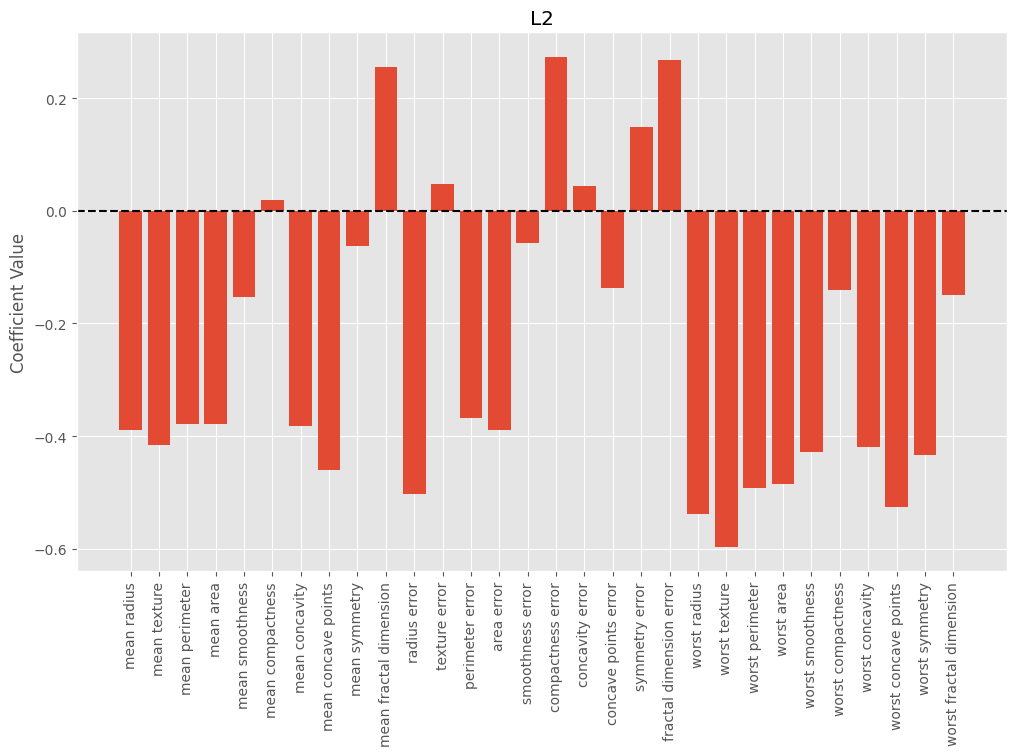

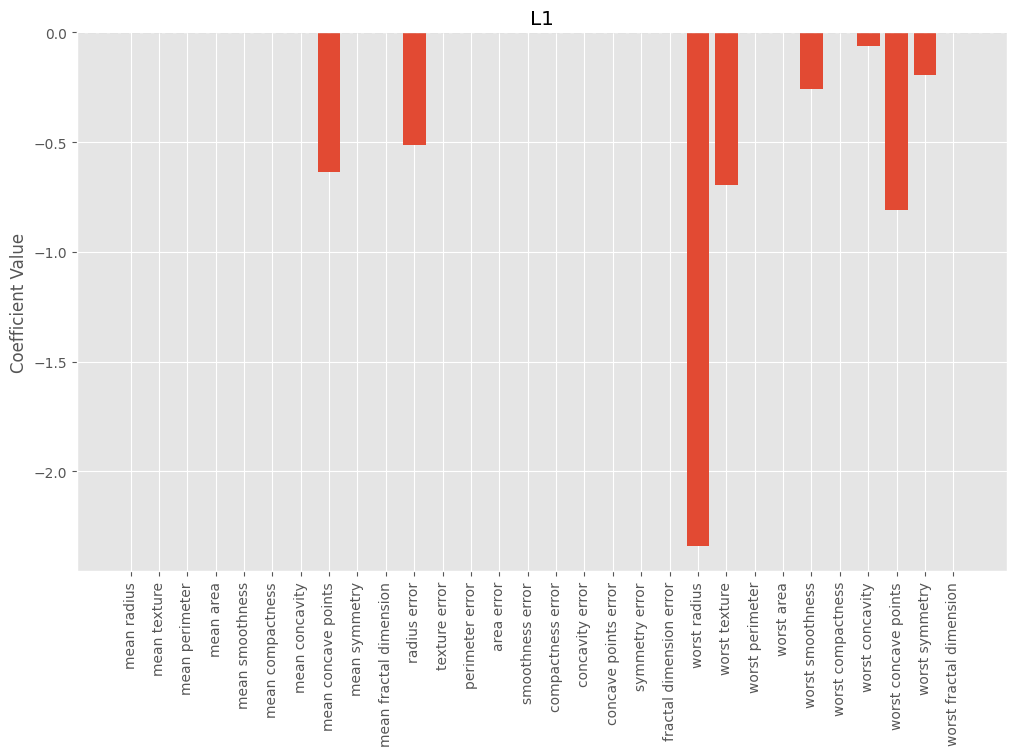

In [10]:
# --- YOUR TASK ---

# TODO: Use the 'plot_coefficients' helper function to plot the coefficients
# for the L2 model.
plot_coefficients(l2_model, feature_names, 'L2')

# TODO: Use the 'plot_coefficients' helper function to plot the coefficients
# for the L1 model.
plot_coefficients(l1_model, feature_names, 'L1')

# --- End of YOUR TASK ---

### **Your Task 3: Analyze L1 vs. L2 Coefficients**

**Instructions:** Compare the two plots of coefficients you just generated.

<br/>

**Question 3.1:** What is the most obvious difference between the two plots? How many features did the L1 model set to (or very near) zero? How many did the L2 model set to zero?

**Your Answer 3.1:**
<p dir="rtl">
در این مثال L2 مقدار پارامتر ها را به سمت صفر میل میدهد(در اینجا 5 پارامتر تقریبا صفر) اما در L1 مقدار پارامترها عموما صفر میشوند (در اینجا فقط 8 پارامتر غیر صفر باقی ماندند)
</p>
<br/>

**Question 3.2:** Which model (L1 or L2) performs feature selection? Explain how this difference is caused by the L1 penalty term ($||\theta||_1$) versus the L2 penalty term ($||\theta||_2^2$).

**Your Answer 3.2:**
<p dir="rtl">
L1 انتخاب ویژگی را انجام میدهد. طبق نمودار این دو جریمه، میدانیم که نمایش کانتوری L2 به صورت بیضی (دایره) است که تمامی نقاط روی محیط بیضی خطای یکسانی دارند. اما در L1 روی رئوس مربع های کانتور مقدار خطا یکسان و مینیمم است (نسبت به اضلاع مربع). این نقاط راسی، روی محورهای مختصات پارامترها قرار دارند. در نتیجه در L1 مقدار پارامترها صفر میشود چون مدل تمایل دارد تا به سمت نقاط راسی حرکت کند. از آن جایی که نقاط راسی روی محورها قرار گرفته اند و روی هر محور، یک پارامتر تغییر میکند و سایر پارامترها صفر باقی میمانند، حذف ویژگی (انتخاب ویژگی) اتفاق می افتد. 
</p>

<br/>

<div style="background-color: #e6f7ff; padding: 20px; border-radius: 10px; border: 1px solid #b3e0ff; text-align: center;">
  <h3 style="margin:0; color:#0056b3;">Congratulations!</h3>
  <p style="color:#333; font-size: 1.1em;">You have completed the second practical homework.</p>
</div>